# Making the Most of your Colab Subscription



In [ ]:
!pip install pandas scikit-learn -q

Label: Data Preprocessing & Dataset Preparation
This cell does 7 things:

1. Load — reads finalData.csv (12,477 labeled rows)
2. Clean — removes duplicates and texts shorter than 5 characters
3. Normalize — Arabic-specific text cleaning (removes URLs, mentions, diacritics, normalizes alef variants and teh marbuta)
4. Encode labels — maps Negative→0, Neutral→1, Positive→2
5. Class weights — computes balanced weights to handle class imbalance (Neutral=57%, Negative=27%, Positive=16%)
6. Stratified split — 70% train / 15% val / 15% test, maintaining class distribution in each split
7. Save — outputs 5 files: full dataset, train/val/test CSVs, and class weights JSON


In [ ]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# ══════════════════════════════════════════
# 1. LOAD DATA
# ══════════════════════════════════════════
df = pd.read_csv("finalData.csv")
df["text"] = df["text"].fillna("")
print(f"✅ Loaded: {df.shape}")

# ══════════════════════════════════════════
# 2. REMOVE DUPLICATES & SHORT TEXTS
# ══════════════════════════════════════════
df = df.drop_duplicates(subset=["text"], keep="first")
df = df[df["text"].str.len() >= 5]
df = df.reset_index(drop=True)
print(f"✅ After cleaning: {df.shape}")

# ══════════════════════════════════════════
# 3. TEXT NORMALIZATION FUNCTION
# ══════════════════════════════════════════
def normalize_text(text):
    # Replace newlines with space
    text = text.replace("\n", " ")

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove @mentions
    text = re.sub(r"@\w+", "", text)

    # Normalize Arabic alef variants → ا
    text = re.sub("[إأآا]", "ا", text)

    # Normalize teh marbuta
    text = re.sub("ة", "ه", text)

    # Remove Arabic diacritics (tashkeel)
    text = re.sub(r"[\u064B-\u065F]", "", text)

    # Remove tatweel (stretching)
    text = re.sub(r"ـ", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

df["text_clean"] = df["text"].apply(normalize_text)
print("✅ Text normalization done")

# ══════════════════════════════════════════
# 4. ENCODE LABELS
# ══════════════════════════════════════════
label_map = {"Negative": 0, "Neutral": 1, "Positive": 2}
df["label"] = df["Sentiment"].map(label_map)
print("✅ Labels encoded: Negative=0, Neutral=1, Positive=2")
print(df["label"].value_counts())

# ══════════════════════════════════════════
# 5. COMPUTE CLASS WEIGHTS (for imbalance)
# ══════════════════════════════════════════
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1, 2])
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=df["label"]
)
class_weights = dict(zip(classes, weights))
print(f"\n✅ Class weights (use during training):")
print(f"   Negative (0): {class_weights[0]:.3f}")
print(f"   Neutral  (1): {class_weights[1]:.3f}")
print(f"   Positive (2): {class_weights[2]:.3f}")

# ══════════════════════════════════════════
# 6. STRATIFIED SPLIT — 70/15/15
# ══════════════════════════════════════════
# First split: 70% train, 30% temp
train_df, temp_df = train_test_split(
    df, test_size=0.30,
    stratify=df["label"],
    random_state=42
)

# Second split: 50/50 of temp → 15% val, 15% test
val_df, test_df = train_test_split(
    temp_df, test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print(f"\n✅ Split complete:")
print(f"   Train : {len(train_df)} rows ({len(train_df)/len(df)*100:.1f}%)")
print(f"   Val   : {len(val_df)} rows ({len(val_df)/len(df)*100:.1f}%)")
print(f"   Test  : {len(test_df)} rows ({len(test_df)/len(df)*100:.1f}%)")

print(f"\n✅ Label distribution in each split:")
print("Train:\n", train_df["label"].value_counts())
print("Val:\n", val_df["label"].value_counts())
print("Test:\n", test_df["label"].value_counts())

# ══════════════════════════════════════════
# 7. SAVE ALL OUTPUTS
# ══════════════════════════════════════════
df.to_csv("/content/data_full_clean.csv", index=False, encoding="utf-8-sig")
train_df.to_csv("/content/data_train.csv", index=False, encoding="utf-8-sig")
val_df.to_csv("/content/data_val.csv", index=False, encoding="utf-8-sig")
test_df.to_csv("/content/data_test.csv", index=False, encoding="utf-8-sig")

# Save class weights for use in training
import json
with open("/content/class_weights.json", "w") as f:
    json.dump({str(k): v for k, v in class_weights.items()}, f)

print("\n✅ All files saved:")
print("   data_full_clean.csv  — full cleaned dataset")
print("   data_train.csv       — 70% training set")
print("   data_val.csv         — 15% validation set")
print("   data_test.csv        — 15% test set")
print("   class_weights.json   — use during model training")

✅ Loaded: (12477, 2)
✅ After cleaning: (12425, 2)
✅ Text normalization done
✅ Labels encoded: Negative=0, Neutral=1, Positive=2
label
1    7086
0    3307
2    2032
Name: count, dtype: int64

✅ Class weights (use during training):
   Negative (0): 1.252
   Neutral  (1): 0.584
   Positive (2): 2.038

✅ Split complete:
   Train : 8697 rows (70.0%)
   Val   : 1864 rows (15.0%)
   Test  : 1864 rows (15.0%)

✅ Label distribution in each split:
Train:
 label
1    4960
0    2315
2    1422
Name: count, dtype: int64
Val:
 label
1    1063
0     496
2     305
Name: count, dtype: int64
Test:
 label
1    1063
0     496
2     305
Name: count, dtype: int64

✅ All files saved:
   data_full_clean.csv  — full cleaned dataset
   data_train.csv       — 70% training set
   data_val.csv         — 15% validation set
   data_test.csv        — 15% test set
   class_weights.json   — use during model training


In [ ]:
!pip install transformers sentencepiece sacremoses datasets -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.5/897.5 kB 10.9 MB/s eta 0:00:00


Label: Tokenization Analysis & OOV (Out-of-Vocabulary) Study

This cell does 5 things:

1. Load tokenizer — uses Jais-family-590m tokenizer (same vocab as Jais-7B, 84,992 tokens, BPE-based)
2. Token length analysis — computes mean/median/max token counts across training set to determine optimal max_length=64 (95th percentile = 45 tokens)
3. OOV analysis — checks how many tokens are unknown (<unk>) — result was 0.00% OOV, confirming Jais BPE tokenizer handles all Arabic+English code-switched words by splitting into subwords
4. Tokenization examples — shows how 3 real code-switched sentences are tokenized (Arabic + English mixed)
5. Save — outputs data_train_tokenized.csv

In [ ]:
import pandas as pd
import numpy as np
from transformers import AutoTokenizer
from collections import Counter
import warnings
warnings.filterwarnings("ignore")

# ══════════════════════════════════════════
# 1. LOAD DATA
# ══════════════════════════════════════════
train_df = pd.read_csv("/content/data_train.csv")
val_df   = pd.read_csv("/content/data_val.csv")
test_df  = pd.read_csv("/content/data_test.csv")
print(f"✅ Loaded: Train={len(train_df)} | Val={len(val_df)} | Test={len(test_df)}")

# ══════════════════════════════════════════
# 2. LOAD JAIS TOKENIZER
# ══════════════════════════════════════════
print("⏳ Loading Jais tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(
    "inceptionai/jais-family-590m",  # lightweight Jais — same tokenizer as 8B
    trust_remote_code=True
)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print(f"✅ Tokenizer loaded")
print(f"   Vocab size: {tokenizer.vocab_size:,}")
print(f"   Pad token: {tokenizer.pad_token}")
print(f"   EOS token: {tokenizer.eos_token}")

# ══════════════════════════════════════════
# 3. TOKENIZE & ANALYZE
# ══════════════════════════════════════════
def tokenize_text(text):
    return tokenizer.tokenize(str(text))

# Tokenize all texts
print("\n⏳ Tokenizing all texts...")
train_df["tokens"]     = train_df["text_clean"].apply(tokenize_text)
train_df["token_count"] = train_df["tokens"].apply(len)

print(f"✅ Tokenization complete")
print(f"\n📊 Token Length Stats:")
print(f"   Mean  : {train_df['token_count'].mean():.1f}")
print(f"   Median: {train_df['token_count'].median():.1f}")
print(f"   Max   : {train_df['token_count'].max()}")
print(f"   Min   : {train_df['token_count'].min()}")
print(f"   95th% : {train_df['token_count'].quantile(0.95):.0f}")
print(f"\n💡 Recommended max_length for training: {int(train_df['token_count'].quantile(0.95))}")

# Texts that exceed 128 tokens
over_128 = (train_df["token_count"] > 128).sum()
print(f"\n⚠️  Texts over 128 tokens: {over_128} ({over_128/len(train_df)*100:.1f}%) — will be truncated")

# ══════════════════════════════════════════
# 4. OOV ANALYSIS
# ══════════════════════════════════════════
print("\n⏳ Analyzing OOV tokens...")

# In subword tokenizers, OOV shows as <unk> or broken subwords starting with ##
# For Jais (BPE-based), unknown tokens appear as <unk>
unk_token = tokenizer.unk_token

oov_counts = []
oov_examples = []

for text, tokens in zip(train_df["text_clean"], train_df["tokens"]):
    oov = [t for t in tokens if t == unk_token]
    oov_counts.append(len(oov))
    if len(oov) > 0:
        oov_examples.append({"text": text, "oov_count": len(oov), "tokens": tokens})

train_df["oov_count"] = oov_counts
total_tokens = train_df["token_count"].sum()
total_oov    = train_df["oov_count"].sum()

print(f"✅ OOV Analysis complete:")
print(f"   Total tokens      : {total_tokens:,}")
print(f"   Total OOV tokens  : {total_oov:,}")
print(f"   OOV rate          : {total_oov/total_tokens*100:.2f}%")
print(f"   Texts with OOV    : {(train_df['oov_count']>0).sum()}")

if len(oov_examples) > 0:
    print(f"\n📌 Sample texts with OOV tokens:")
    for ex in oov_examples[:3]:
        print(f"   Text   : {ex['text'][:80]}")
        print(f"   OOV cnt: {ex['oov_count']}")
        print()
else:
    print("\n✅ No OOV tokens found — Jais subword tokenizer handles all words!")
    print("   This is expected — BPE tokenizers split unknown words into subwords")
    print("   instead of marking them as <unk>")

# ══════════════════════════════════════════
# 5. SHOW TOKENIZATION EXAMPLES
# ══════════════════════════════════════════
print("\n📌 Tokenization examples (code-switched text):")
examples = [
    "ما تاخدش الحاجة For Granted عشان ما تزولش",
    "والله بتحب Stranger Things كتير",
    "الـ EDA في العالم مهمه جداً"
]
for ex in examples:
    tokens = tokenizer.tokenize(ex)
    print(f"   Text  : {ex}")
    print(f"   Tokens: {tokens}")
    print()

# Save tokenized data
train_df.to_csv("/content/data_train_tokenized.csv", index=False)
print("✅ Saved tokenized train data to data_train_tokenized.csv")

✅ Loaded: Train=8697 | Val=1864 | Test=1864
⏳ Loading Jais tokenizer...


config.json: 0.00B [00:00, ?B/s]

configuration_jais.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/inceptionai/jais-family-590m:
- configuration_jais.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


tokenizer_config.json:   0%|          | 0.00/247 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/131 [00:00<?, ?B/s]

✅ Tokenizer loaded
   Vocab size: 84,992
   Pad token: <|endoftext|>
   EOS token: <|endoftext|>

⏳ Tokenizing all texts...
✅ Tokenization complete

📊 Token Length Stats:
   Mean  : 17.4
   Median: 14.0
   Max   : 98
   Min   : 2
   95th% : 45

💡 Recommended max_length for training: 45

⚠️  Texts over 128 tokens: 0 (0.0%) — will be truncated

⏳ Analyzing OOV tokens...
✅ OOV Analysis complete:
   Total tokens      : 151,620
   Total OOV tokens  : 0
   OOV rate          : 0.00%
   Texts with OOV    : 0

✅ No OOV tokens found — Jais subword tokenizer handles all words!
   This is expected — BPE tokenizers split unknown words into subwords
   instead of marking them as <unk>

📌 Tokenization examples (code-switched text):
   Text  : ما تاخدش الحاجة For Granted عشان ما تزولش
   Tokens: ['ÙħØ§', 'ĠØª', 'Ø§Ø®Ø¯', 'Ø´', 'ĠØ§ÙĦØŃØ§Ø¬Ø©', 'ĠFor', 'ĠGr', 'anted', 'ĠØ¹Ø´Ø§ÙĨ', 'ĠÙħØ§', 'ĠØªØ²ÙĪÙĦ', 'Ø´']

   Text  : والله بتحب Stranger Things كتير
   Tokens: ['ÙĪØ§ÙĦÙĦÙĩ', 'ĠØ¨ØªØŃ', 'Ø¨', 'ĠStr', 

In [ ]:
!pip install transformers peft accelerate bitsandbytes datasets scikit-learn -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 9.6 MB/s eta 0:00:00


Label: PyTorch + HuggingFace — Jais LoRA (PEFT) — FAILED ATTEMPT

1. This used jais-family-590m (smaller model) instead of jais-adapted-7b. It failed because of the evaluation_strategy → eval_strategy rename in newer transformers versions.

In [ ]:
import os
os.environ["WANDB_DISABLED"] = "true"

import torch
import pandas as pd
import numpy as np
import json
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    BitsAndBytesConfig,
)
from peft import LoraConfig, get_peft_model, TaskType, prepare_model_for_kbit_training
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix
)
import warnings
warnings.filterwarnings("ignore")

# ══════════════════════════════════════════
# 1. LOAD DATA + CLASS WEIGHTS
# ══════════════════════════════════════════
train_df = pd.read_csv("/content/data_train.csv")
val_df   = pd.read_csv("/content/data_val.csv")
test_df  = pd.read_csv("/content/data_test.csv")

with open("/content/class_weights.json") as f:
    cw = json.load(f)
class_weights = torch.tensor([cw["0"], cw["1"], cw["2"]], dtype=torch.float)

print(f"✅ Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f"✅ Class weights: {class_weights.tolist()}")

# ══════════════════════════════════════════
# 2. LOAD JAIS TOKENIZER
# ══════════════════════════════════════════
MODEL_NAME = "inceptionai/jais-family-590m"
print("⏳ Loading Jais tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True
)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
print("✅ Tokenizer loaded")

# ══════════════════════════════════════════
# 3. TOKENIZE DATASETS
# ══════════════════════════════════════════
def tokenize(examples):
    return tokenizer(
        examples["text_clean"],
        truncation=True,
        padding="max_length",
        max_length=64          # ✅ optimized based on OOV analysis
    )

# Convert to HuggingFace Dataset format
train_ds = Dataset.from_pandas(train_df[["text_clean", "label"]])
val_ds   = Dataset.from_pandas(val_df[["text_clean", "label"]])
test_ds  = Dataset.from_pandas(test_df[["text_clean", "label"]])

# Tokenize
train_ds = train_ds.map(tokenize, batched=True)
val_ds   = val_ds.map(tokenize, batched=True)
test_ds  = test_ds.map(tokenize, batched=True)

# Rename label column to what HuggingFace Trainer expects
train_ds = train_ds.rename_column("label", "labels")
val_ds   = val_ds.rename_column("label", "labels")
test_ds  = test_ds.rename_column("label", "labels")

# Set format to PyTorch tensors
train_ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
val_ds.set_format("torch",   columns=["input_ids", "attention_mask", "labels"])
test_ds.set_format("torch",  columns=["input_ids", "attention_mask", "labels"])
print("✅ All datasets tokenized and formatted")

# ══════════════════════════════════════════
# 4. LOAD MODEL WITH 4-BIT QUANTIZATION
# ══════════════════════════════════════════
print("⏳ Loading Jais model in 4-bit (this takes 3-5 min)...")
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
)
model.config.pad_token_id = tokenizer.pad_token_id
print("✅ Model loaded with 4-bit quantization")

# ══════════════════════════════════════════
# 5. APPLY LoRA
# ══════════════════════════════════════════
# Prepare model for k-bit training (required before LoRA)
model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=16,                              # rank — higher = more capacity
    lora_alpha=32,                     # scaling factor
    target_modules=["q_proj", "v_proj"],  # attention layers to adapt
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.SEQ_CLS,
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()
print("✅ LoRA applied — only training adapter layers")

# ══════════════════════════════════════════
# 6. CUSTOM TRAINER WITH CLASS WEIGHTS
# ══════════════════════════════════════════
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weights = class_weights.to(logits.device)
        loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
        loss = loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss

# ══════════════════════════════════════════
# 7. METRICS FUNCTION
# ══════════════════════════════════════════
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy"  : round(accuracy_score(labels, preds), 4),
        "macro_f1"  : round(f1_score(labels, preds, average="macro"), 4),
        "precision" : round(precision_score(labels, preds, average="macro"), 4),
        "recall"    : round(recall_score(labels, preds, average="macro"), 4),
    }

# ══════════════════════════════════════════
# 8. TRAINING ARGUMENTS
# ══════════════════════════════════════════
training_args = TrainingArguments(
    output_dir="./jais_lora_output",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,    # effective batch = 32
    learning_rate=1e-4,
    warmup_ratio=0.1,
    weight_decay=0.01,
    evaluation_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=True,
    logging_steps=100,
    report_to="none",
)

# ══════════════════════════════════════════
# 9. TRAIN
# ══════════════════════════════════════════
trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
)

print("\n⏳ Starting LoRA training — 3 epochs...")
print("   Expected time: 45-90 min on T4")
print("   You will see eval results after each epoch\n")
trainer.train()
print("✅ Training complete!")

# ══════════════════════════════════════════
# 10. EVALUATE ON TEST SET
# ══════════════════════════════════════════
print("\n📊 Final Test Set Results:")
results = trainer.evaluate(test_ds)
for k, v in results.items():
    print(f"   {k}: {v}")

# Confusion matrix
preds_out = trainer.predict(test_ds)
preds  = np.argmax(preds_out.predictions, axis=1)
labels = preds_out.label_ids
cm     = confusion_matrix(labels, preds)

print("\n📊 Confusion Matrix:")
print(f"{'':15} Predicted:")
print(f"{'':15} Neg    Neu    Pos")
for i, name in enumerate(["Negative", "Neutral ", "Positive"]):
    print(f"Actual {name}: {cm[i]}")

# Save everything
results_df = pd.DataFrame([results])
results_df.to_csv("/content/lora_results.csv", index=False)
trainer.save_model("/content/jais_lora_model")
tokenizer.save_pretrained("/content/jais_lora_model")

print("\n✅ Results saved to lora_results.csv")
print("✅ Model saved to jais_lora_model/")
print("\n🎉 PyTorch + LoRA pipeline complete!")




✅ Train: 8697 | Val: 1864 | Test: 1864
✅ Class weights: [1.2523939609527588, 0.5844858288764954, 2.038221836090088]
⏳ Loading Jais tokenizer...


✅ Tokenizer loaded


Map:   0%|          | 0/8697 [00:00<?, ? examples/s]

Map:   0%|          | 0/1864 [00:00<?, ? examples/s]

Map:   0%|          | 0/1864 [00:00<?, ? examples/s]

✅ All datasets tokenized and formatted
⏳ Loading Jais model in 4-bit (this takes 3-5 min)...


modeling_jais.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/inceptionai/jais-family-590m:
- modeling_jais.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


ImportError: cannot import name 'find_pruneable_heads_and_indices' from 'transformers.pytorch_utils' (/usr/local/lib/python3.12/dist-packages/transformers/pytorch_utils.py)

**now using bloom 560m not optimal at all but just to see what happens **:


In [ ]:
import os
os.environ["WANDB_DISABLED"] = "true"

import torch
import pandas as pd
import numpy as np
import json
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    BitsAndBytesConfig,
)
from peft import LoraConfig, get_peft_model, TaskType, prepare_model_for_kbit_training
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix
)
import warnings
warnings.filterwarnings("ignore")

# ══════════════════════════════════════════
# 1. LOAD DATA + CLASS WEIGHTS
# ══════════════════════════════════════════
train_df = pd.read_csv("/content/data_train.csv")
val_df   = pd.read_csv("/content/data_val.csv")
test_df  = pd.read_csv("/content/data_test.csv")

with open("/content/class_weights.json") as f:
    cw = json.load(f)
class_weights = torch.tensor([cw["0"], cw["1"], cw["2"]], dtype=torch.float)

print(f"✅ Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f"✅ Class weights: {class_weights.tolist()}")

# ══════════════════════════════════════════
# 2. LOAD BLOOM TOKENIZER
# ══════════════════════════════════════════
MODEL_NAME = "bigscience/bloom-560m"  # ✅ multilingual, Arabic+English, no import errors
print("⏳ Loading BLOOM tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
print(f"✅ Tokenizer loaded | Vocab size: {tokenizer.vocab_size:,}")

# ══════════════════════════════════════════
# 3. TOKENIZE DATASETS
# ══════════════════════════════════════════
def tokenize(examples):
    return tokenizer(
        examples["text_clean"],
        truncation=True,
        padding="max_length",
        max_length=64
    )

train_ds = Dataset.from_pandas(train_df[["text_clean", "label"]])
val_ds   = Dataset.from_pandas(val_df[["text_clean", "label"]])
test_ds  = Dataset.from_pandas(test_df[["text_clean", "label"]])

train_ds = train_ds.map(tokenize, batched=True)
val_ds   = val_ds.map(tokenize, batched=True)
test_ds  = test_ds.map(tokenize, batched=True)

train_ds = train_ds.rename_column("label", "labels")
val_ds   = val_ds.rename_column("label", "labels")
test_ds  = test_ds.rename_column("label", "labels")

train_ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
val_ds.set_format("torch",   columns=["input_ids", "attention_mask", "labels"])
test_ds.set_format("torch",  columns=["input_ids", "attention_mask", "labels"])
print("✅ All datasets tokenized and formatted")

# ══════════════════════════════════════════
# 4. LOAD MODEL WITH 4-BIT QUANTIZATION
# ══════════════════════════════════════════
print("⏳ Loading BLOOM model in 4-bit...")
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    quantization_config=bnb_config,
    device_map="auto",
)
model.config.pad_token_id = tokenizer.pad_token_id
print("✅ BLOOM model loaded with 4-bit quantization")

# ══════════════════════════════════════════
# 5. APPLY LoRA
# ══════════════════════════════════════════
model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["query_key_value"],  # ✅ BLOOM uses this instead of q_proj/v_proj
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.SEQ_CLS,
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()
print("✅ LoRA applied")

# ══════════════════════════════════════════
# 6. CUSTOM TRAINER WITH CLASS WEIGHTS
# ══════════════════════════════════════════
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weights = class_weights.to(logits.device)
        loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
        loss = loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss

# ══════════════════════════════════════════
# 7. METRICS FUNCTION
# ══════════════════════════════════════════
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy"  : round(accuracy_score(labels, preds), 4),
        "macro_f1"  : round(f1_score(labels, preds, average="macro"), 4),
        "precision" : round(precision_score(labels, preds, average="macro"), 4),
        "recall"    : round(recall_score(labels, preds, average="macro"), 4),
    }

# ══════════════════════════════════════════
# 8. TRAINING ARGUMENTS
# ══════════════════════════════════════════
training_args = TrainingArguments(
    output_dir="./bloom_lora_output",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,
    learning_rate=1e-4,
    warmup_ratio=0.1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=True,
    logging_steps=100,
    report_to="none",
)

# ══════════════════════════════════════════
# 9. TRAIN
# ══════════════════════════════════════════
trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
)

print("\n⏳ Starting LoRA training — 3 epochs...")
print("   Expected time: 15-25 min on T4\n")
trainer.train()
print("✅ Training complete!")

# ══════════════════════════════════════════
# 10. EVALUATE ON TEST SET
# ══════════════════════════════════════════
print("\n📊 Final Test Set Results:")
results = trainer.evaluate(test_ds)
for k, v in results.items():
    print(f"   {k}: {v}")

# Confusion matrix
preds_out = trainer.predict(test_ds)
preds  = np.argmax(preds_out.predictions, axis=1)
labels = preds_out.label_ids
cm     = confusion_matrix(labels, preds)

print("\n📊 Confusion Matrix:")
print(f"{'':15} Neg  Neu  Pos")
for i, name in enumerate(["Negative", "Neutral ", "Positive"]):
    print(f"Actual {name}: {cm[i]}")

# Save results + model
results_df = pd.DataFrame([results])
results_df.to_csv("/content/drive/MyDrive/CSCI316_Project/bloom_lora_results.csv", index=False)
trainer.save_model("/content/drive/MyDrive/CSCI316_Project/bloom_lora_model")
tokenizer.save_pretrained("/content/drive/MyDrive/CSCI316_Project/bloom_lora_model")

print("\n✅ Results saved to Drive: bloom_lora_results.csv")
print("✅ Model saved to Drive: bloom_lora_model/")
print("\n🎉 PyTorch + LoRA pipeline complete!")

✅ Train: 8697 | Val: 1864 | Test: 1864
✅ Class weights: [1.2523939609527588, 0.5844858288764954, 2.038221836090088]
⏳ Loading BLOOM tokenizer...
✅ Tokenizer loaded | Vocab size: 250,680


Map:   0%|          | 0/8697 [00:00<?, ? examples/s]

Map:   0%|          | 0/1864 [00:00<?, ? examples/s]

Map:   0%|          | 0/1864 [00:00<?, ? examples/s]

✅ All datasets tokenized and formatted
⏳ Loading BLOOM model in 4-bit...


Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

BloomForSequenceClassification LOAD REPORT from: bigscience/bloom-560m
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ BLOOM model loaded with 4-bit quantization


warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


trainable params: 1,575,936 || all params: 560,793,600 || trainable%: 0.2810
✅ LoRA applied

⏳ Starting LoRA training — 3 epochs...
   Expected time: 15-25 min on T4



In [1]:
!pip install tensorflow transformers datasets scikit-learn -q

In [5]:
from google.colab import drive
drive.mount('/content/drive')

import shutil, os
project_folder = '/content/drive/MyDrive/CSCI316_Project/'
for f in os.listdir(project_folder):
    src = f'{project_folder}{f}'
    dst = f'/content/{f}'
    if os.path.isfile(src):
        shutil.copy(src, dst)
        print(f'✅ Restored: {f}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/CSCI316_Project/'

In [4]:
import os
print(os.listdir('/content/drive/MyDrive/'))

['Getting started.pdf', 'Colab Notebooks']


In [6]:
import os
print(os.listdir('/content/drive/MyDrive/'))

['Getting started.pdf', 'Colab Notebooks', 'Proj316_files.zip']


In [7]:
import zipfile
import shutil
import os

# Extract zip
with zipfile.ZipFile('/content/drive/MyDrive/Proj316_files.zip', 'r') as z:
    z.extractall('/content/')
    print("Extracted files:", z.namelist())

# Check needed files
needed = ['data_train.csv', 'data_val.csv', 'data_test.csv', 'class_weights.json']
for f in needed:
    exists = os.path.exists(f'/content/{f}')
    print(f"{'✅' if exists else '❌'} {f}")

Extracted files: ['class_weights.json', 'data_full_clean.csv', 'data_test.csv', 'data_train.csv', 'data_train_tokenized.csv', 'data_val.csv', 'finalData (1).csv']
✅ data_train.csv
✅ data_val.csv
✅ data_test.csv
✅ class_weights.json


In [8]:
import tensorflow as tf
import os

# Check GPU
print("GPUs:", tf.config.list_physical_devices('GPU'))
print("TF version:", tf.__version__)

# Check files
needed = ['data_train.csv', 'data_val.csv', 'data_test.csv', 'class_weights.json']
for f in needed:
    exists = os.path.exists(f'/content/{f}')
    print(f"{'✅' if exists else '❌'} {f}")

GPUs: []
TF version: 2.19.0
✅ data_train.csv
✅ data_val.csv
✅ data_test.csv
✅ class_weights.json


In [9]:
!pip install tensorflow[and-cuda] -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.3/363.3 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.5/22.5 MB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.9/24.9 MB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 895.7/895.7 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 577.2/577.2 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.5/192.5 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.3/130.3 MB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 217.6/217.6 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.0/199.0 MB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.3/21.3 MB 76.0 MB/s eta 0:00:00


In [1]:
!pip install tensorflow[and-cuda] transformers datasets scikit-learn -q

In [1]:
import zipfile, shutil, os
from google.colab import drive
drive.mount('/content/drive')

with zipfile.ZipFile('/content/drive/MyDrive/Proj316_files.zip', 'r') as z:
    z.extractall('/content/')
print("✅ Files restored")

import tensorflow as tf
print("TF version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
✅ Files restored
TF version: 2.19.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
import os
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import json
import tensorflow as tf
from transformers import (
    AutoTokenizer,
    TFAutoModelForSequenceClassification,
)
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix
)
import warnings
warnings.filterwarnings("ignore")

# ══════════════════════════════════════════
# 1. LOAD DATA + CLASS WEIGHTS
# ══════════════════════════════════════════
train_df = pd.read_csv("/content/data_train.csv")
val_df   = pd.read_csv("/content/data_val.csv")
test_df  = pd.read_csv("/content/data_test.csv")

with open("/content/class_weights.json") as f:
    cw = json.load(f)

class_weights = {0: float(cw["0"]), 1: float(cw["1"]), 2: float(cw["2"])}
print(f"✅ Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f"✅ Class weights: {class_weights}")
print(f"✅ GPU: {tf.config.list_physical_devices('GPU')}")

# ══════════════════════════════════════════
# 2. LOAD TOKENIZER
# ══════════════════════════════════════════
MODEL_NAME = "bigscience/bloom-560m"
print(f"⏳ Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
print(f"✅ Tokenizer loaded | Vocab: {tokenizer.vocab_size:,}")

# ══════════════════════════════════════════
# 3. TOKENIZE + CONVERT TO TF DATASET
# ══════════════════════════════════════════
def make_tf_dataset(df, batch_size=16, shuffle=False):
    texts  = df["text_clean"].tolist()
    labels = df["label"].tolist()

    encodings = tokenizer(
        texts,
        truncation=True,
        padding="max_length",
        max_length=64,
        return_tensors="tf"
    )

    dataset = tf.data.Dataset.from_tensor_slices((
        {
            "input_ids":      encodings["input_ids"],
            "attention_mask": encodings["attention_mask"],
        },
        tf.constant(labels)
    ))

    if shuffle:
        dataset = dataset.shuffle(buffer_size=1000)

    return dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

print("⏳ Creating TF datasets...")
train_ds = make_tf_dataset(train_df, batch_size=16, shuffle=True)
val_ds   = make_tf_dataset(val_df,   batch_size=16)
test_ds  = make_tf_dataset(test_df,  batch_size=16)
print("✅ TF datasets created")

# ══════════════════════════════════════════
# 4. LOAD MODEL — TF VERSION
# ══════════════════════════════════════════
print("⏳ Loading BLOOM TF model...")
model = TFAutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
)
model.config.pad_token_id = tokenizer.pad_token_id
print("✅ TF Model loaded")
print(f"   Total layers: {len(model.layers)}")

# ══════════════════════════════════════════
# 5. COMPILE — KERAS STYLE
# ══════════════════════════════════════════
optimizer = tf.keras.optimizers.Adam(learning_rate=2e-5)
loss      = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
metrics   = [tf.keras.metrics.SparseCategoricalAccuracy("accuracy")]

model.compile(
    optimizer=optimizer,
    loss=loss,
    metrics=metrics
)
print("✅ Model compiled — Keras style")

# ══════════════════════════════════════════
# 6. CALLBACKS
# ══════════════════════════════════════════
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=2,
        verbose=1,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        verbose=1
    )
]

# ══════════════════════════════════════════
# 7. TRAIN — KERAS model.fit()
# ══════════════════════════════════════════
print("\n⏳ Starting TF/Keras Full Fine-Tuning — 3 epochs...")
print("   Using model.fit() — Keras API")
print("   Expected time: 20-40 min on T4\n")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=callbacks,
    class_weight=class_weights,
    verbose=1
)
print("✅ Keras training complete!")

# ══════════════════════════════════════════
# 8. EVALUATE ON TEST SET
# ══════════════════════════════════════════
print("\n📊 Evaluating on test set...")
all_preds  = []
all_labels = []

for batch_inputs, batch_labels in test_ds:
    outputs = model(batch_inputs, training=False)
    preds   = tf.argmax(outputs.logits, axis=1).numpy()
    all_preds.extend(preds)
    all_labels.extend(batch_labels.numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

accuracy  = round(accuracy_score(all_labels, all_preds), 4)
macro_f1  = round(f1_score(all_labels, all_preds, average="macro"), 4)
precision = round(precision_score(all_labels, all_preds, average="macro"), 4)
recall    = round(recall_score(all_labels, all_preds, average="macro"), 4)
cm        = confusion_matrix(all_labels, all_preds)

print(f"\n📊 TF/Keras Full Fine-Tuning Results:")
print(f"   Accuracy  : {accuracy}")
print(f"   Macro F1  : {macro_f1}")
print(f"   Precision : {precision}")
print(f"   Recall    : {recall}")

print(f"\n📊 Confusion Matrix:")
print(f"{'':15} Neg  Neu  Pos")
for i, name in enumerate(["Negative", "Neutral ", "Positive"]):
    print(f"Actual {name}: {cm[i]}")

# ══════════════════════════════════════════
# 9. SAVE RESULTS
# ══════════════════════════════════════════
results = {
    "framework" : "TensorFlow/Keras",
    "model"     : MODEL_NAME,
    "strategy"  : "Full Fine-Tuning",
    "accuracy"  : accuracy,
    "macro_f1"  : macro_f1,
    "precision" : precision,
    "recall"    : recall,
}

results_df = pd.DataFrame([results])
results_df.to_csv("/content/keras_fullft_results.csv", index=False)

# Save to Drive
import zipfile
with zipfile.ZipFile('/content/drive/MyDrive/Proj316_files.zip', 'a') as z:
    z.write('/content/keras_fullft_results.csv', 'keras_fullft_results.csv')

print("\n✅ Results saved!")
print("\n🎉 TensorFlow/Keras Full Fine-Tuning complete!")

ImportError: cannot import name 'TFAutoModelForSequenceClassification' from 'transformers' (/usr/local/lib/python3.12/dist-packages/transformers/__init__.py)

In [4]:
!pip install transformers[tf-cpu] tensorflow -q

In [1]:
!pip install transformers[tf-cpu] tensorflow datasets scikit-learn -q

In [2]:
import zipfile, os
from google.colab import drive
drive.mount('/content/drive')

with zipfile.ZipFile('/content/drive/MyDrive/Proj316_files.zip', 'r') as z:
    z.extractall('/content/')
print("✅ Files restored")

import tensorflow as tf
print("TF version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

# Confirm TFAutoModel works now
from transformers import TFAutoModelForSequenceClassification
print("✅ TFAutoModelForSequenceClassification imported successfully")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Files restored
TF version: 2.19.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


ImportError: cannot import name 'TFAutoModelForSequenceClassification' from 'transformers' (/usr/local/lib/python3.12/dist-packages/transformers/__init__.py)

In [3]:
!pip install transformers==4.40.0 -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.6/137.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 65.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 67.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.2.3 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.40.0 which is incompatible.


In [1]:
!pip install transformers==4.40.0 tensorflow datasets scikit-learn -q

In [2]:
import zipfile, os
from google.colab import drive
drive.mount('/content/drive')

with zipfile.ZipFile('/content/drive/MyDrive/Proj316_files.zip', 'r') as z:
    z.extractall('/content/')
print("✅ Files restored")

import tensorflow as tf
print("TF version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

from transformers import TFAutoModelForSequenceClassification
print("✅ TFAutoModelForSequenceClassification imported successfully")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Files restored
TF version: 2.19.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ TFAutoModelForSequenceClassification imported successfully


In [15]:
!pip install tf_keras -q
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

In [1]:
import os
os.environ["WANDB_DISABLED"] = "true"
os.environ["TF_USE_LEGACY_KERAS"] = "1"  # ✅ add this line

# ══════════════════════════════════════════
# BONUS: TensorFlow/Keras Framework — XLM-RoBERTa
# Beyond Requirements: Additional framework implementation
# using TensorFlow/Keras to demonstrate cross-framework
# transfer learning capabilities
# ══════════════════════════════════════════


BONUS — TensorFlow/Keras Full Fine-Tuning (XLM-RoBERTa)

In [4]:
import os
os.environ["WANDB_DISABLED"] = "true"
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import numpy as np
import pandas as pd
import json
import tensorflow as tf
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import warnings
warnings.filterwarnings("ignore")

# ══════════════════════════════════════════
# 1. LOAD DATA
# ══════════════════════════════════════════
train_df = pd.read_csv("/content/data_train.csv")
val_df   = pd.read_csv("/content/data_val.csv")
test_df  = pd.read_csv("/content/data_test.csv")

with open("/content/class_weights.json") as f:
    cw = json.load(f)
class_weights = {0: float(cw["0"]), 1: float(cw["1"]), 2: float(cw["2"])}
print(f"✅ Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

# ══════════════════════════════════════════
# 2. TOKENIZE
# ══════════════════════════════════════════
MODEL_NAME = "xlm-roberta-base"
tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode(df):
    enc = tokenizer(
        df["text_clean"].tolist(),
        truncation=True,
        padding="max_length",
        max_length=64,
        return_tensors="np"
    )
    return enc["input_ids"], enc["attention_mask"], df["label"].values

train_ids, train_mask, train_labels = encode(train_df)
val_ids,   val_mask,   val_labels   = encode(val_df)
test_ids,  test_mask,  test_labels  = encode(test_df)
print("✅ Tokenization done")

# ══════════════════════════════════════════
# 3. LOAD MODEL
# ══════════════════════════════════════════
print("⏳ Loading XLM-RoBERTa...")
model = TFAutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
)
model.config.pad_token_id = tokenizer.pad_token_id
print("✅ Model loaded")

# ══════════════════════════════════════════
# 4. MANUAL TRAINING LOOP WITH GRADIENT CLIPPING
# ✅ Lower LR + gradient clipping + warmup
# ══════════════════════════════════════════
EPOCHS      = 3
BATCH_SIZE  = 16
total_steps = (len(train_df) // BATCH_SIZE) * EPOCHS

# ✅ Warmup then linear decay
lr_schedule = tf.keras.optimizers.schedules.PolynomialDecay(
    initial_learning_rate=1e-5,   # ✅ much lower LR — was 2e-5
    decay_steps=total_steps,
    end_learning_rate=0.0,
)
optimizer = tf.keras.optimizers.Adam(
    learning_rate=lr_schedule,
    epsilon=1e-8,
    clipnorm=1.0   # ✅ gradient clipping
)

loss_fn   = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
train_acc = tf.keras.metrics.SparseCategoricalAccuracy()
val_acc   = tf.keras.metrics.SparseCategoricalAccuracy()

# ══════════════════════════════════════════
# 5. SHUFFLE + BATCH MANUALLY
# ✅ No tf.data — direct numpy batching avoids pipeline issues
# ══════════════════════════════════════════
def get_batches(ids, mask, labels, batch_size, shuffle=False):
    n = len(labels)
    idx = np.arange(n)
    if shuffle:
        np.random.shuffle(idx)
    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)
        b   = idx[start:end]
        yield ids[b], mask[b], labels[b]

# ══════════════════════════════════════════
# 6. TRAINING
# ══════════════════════════════════════════
print(f"\n⏳ Training XLM-RoBERTa — {EPOCHS} epochs...")
print(f"   LR: 1e-5 | Batch: {BATCH_SIZE} | Gradient clipping: 1.0\n")

best_val_acc = 0
weight_vals  = np.array([class_weights[0], class_weights[1], class_weights[2]])

for epoch in range(EPOCHS):
    print(f"Epoch {epoch+1}/{EPOCHS}")
    train_acc.reset_states()
    val_acc.reset_states()
    total_loss = 0
    n_steps    = 0

    for step, (b_ids, b_mask, b_labels) in enumerate(
        get_batches(train_ids, train_mask, train_labels, BATCH_SIZE, shuffle=True)
    ):
        b_ids    = tf.constant(b_ids)
        b_mask   = tf.constant(b_mask)
        b_labels = tf.constant(b_labels)
        b_weights = tf.constant(weight_vals[b_labels.numpy()])

        with tf.GradientTape() as tape:
            outputs = model(
                {"input_ids": b_ids, "attention_mask": b_mask},
                training=True
            )
            loss = loss_fn(b_labels, outputs.logits, sample_weight=b_weights)

        grads = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))
        train_acc.update_state(b_labels, outputs.logits)
        total_loss += loss.numpy()
        n_steps    += 1

        if step % 100 == 0:
            print(f"   Step {step} | Loss: {loss.numpy():.4f} | Acc: {train_acc.result().numpy():.4f}")

    # Validation
    for b_ids, b_mask, b_labels in get_batches(val_ids, val_mask, val_labels, BATCH_SIZE):
        b_ids    = tf.constant(b_ids)
        b_mask   = tf.constant(b_mask)
        b_labels = tf.constant(b_labels)
        outputs  = model({"input_ids": b_ids, "attention_mask": b_mask}, training=False)
        val_acc.update_state(b_labels, outputs.logits)

    avg_loss = total_loss / n_steps
    v_acc    = val_acc.result().numpy()
    t_acc    = train_acc.result().numpy()
    print(f"   ✅ Epoch {epoch+1} — Avg Loss: {avg_loss:.4f} | Train Acc: {t_acc:.4f} | Val Acc: {v_acc:.4f}\n")

    if v_acc > best_val_acc:
        best_val_acc = v_acc
        model.save_weights("/content/best_weights")
        print(f"   💾 Saved best model — val acc: {best_val_acc:.4f}")

print(f"✅ Training complete! Best val acc: {best_val_acc:.4f}")
model.load_weights("/content/best_weights")

# ══════════════════════════════════════════
# 7. EVALUATE
# ══════════════════════════════════════════
print("\n📊 Evaluating on test set...")
all_preds  = []
all_labels = []

for b_ids, b_mask, b_labels in get_batches(test_ids, test_mask, test_labels, BATCH_SIZE):
    b_ids  = tf.constant(b_ids)
    b_mask = tf.constant(b_mask)
    outputs = model({"input_ids": b_ids, "attention_mask": b_mask}, training=False)
    preds   = tf.argmax(outputs.logits, axis=1).numpy()
    all_preds.extend(preds)
    all_labels.extend(b_labels)

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

accuracy  = round(accuracy_score(all_labels, all_preds), 4)
macro_f1  = round(f1_score(all_labels, all_preds, average="macro"), 4)
precision = round(precision_score(all_labels, all_preds, average="macro"), 4)
recall    = round(recall_score(all_labels, all_preds, average="macro"), 4)
cm        = confusion_matrix(all_labels, all_preds)

print(f"\n📊 TF/Keras Full Fine-Tuning Results:")
print(f"   Accuracy  : {accuracy}")
print(f"   Macro F1  : {macro_f1}")
print(f"   Precision : {precision}")
print(f"   Recall    : {recall}")

print(f"\n📊 Confusion Matrix:")
print(f"{'':15} Neg  Neu  Pos")
for i, name in enumerate(["Negative", "Neutral ", "Positive"]):
    print(f"Actual {name}: {cm[i]}")

# ══════════════════════════════════════════
# 8. SAVE
# ══════════════════════════════════════════
results = {
    "framework" : "TensorFlow/Keras",
    "model"     : MODEL_NAME,
    "strategy"  : "Full Fine-Tuning",
    "accuracy"  : accuracy,
    "macro_f1"  : macro_f1,
    "precision" : precision,
    "recall"    : recall,
}
pd.DataFrame([results]).to_csv("/content/keras_fullft_results.csv", index=False)

import zipfile
with zipfile.ZipFile('/content/drive/MyDrive/Proj316_files.zip', 'a') as z:
    z.write('/content/keras_fullft_results.csv', 'keras_fullft_results.csv')

print("\n✅ Results saved!")
print("🎉 TensorFlow/Keras Full Fine-Tuning complete!")

✅ Train: 8697 | Val: 1864 | Test: 1864
✅ Tokenization done
⏳ Loading XLM-RoBERTa...


All PyTorch model weights were used when initializing TFXLMRobertaForSequenceClassification.

Some weights or buffers of the TF 2.0 model TFXLMRobertaForSequenceClassification were not initialized from the PyTorch model and are newly initialized: ['classifier.dense.weight', 'classifier.dense.bias', 'classifier.out_proj.weight', 'classifier.out_proj.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


✅ Model loaded

⏳ Training XLM-RoBERTa — 3 epochs...
   LR: 1e-5 | Batch: 16 | Gradient clipping: 1.0

Epoch 1/3


   Step 0 | Loss: 1.1825 | Acc: 0.2500
   Step 100 | Loss: 1.3332 | Acc: 0.3651
   Step 200 | Loss: 1.3537 | Acc: 0.3256
   Step 300 | Loss: 1.0202 | Acc: 0.3385
   Step 400 | Loss: 1.1717 | Acc: 0.3591
   Step 500 | Loss: 1.0861 | Acc: 0.3903
   ✅ Epoch 1 — Avg Loss: 1.0756 | Train Acc: 0.4007 | Val Acc: 0.4603

   💾 Saved best model — val acc: 0.4603
Epoch 2/3
   Step 0 | Loss: 0.9130 | Acc: 0.5625
   Step 100 | Loss: 0.9502 | Acc: 0.5433
   Step 200 | Loss: 1.3939 | Acc: 0.5299
   Step 300 | Loss: 0.5961 | Acc: 0.5509
   Step 400 | Loss: 1.1572 | Acc: 0.5608
   Step 500 | Loss: 0.6960 | Acc: 0.5623
   ✅ Epoch 2 — Avg Loss: 0.9309 | Train Acc: 0.5642 | Val Acc: 0.5950

   💾 Saved best model — val acc: 0.5950
Epoch 3/3
   Step 0 | Loss: 0.6694 | Acc: 0.5000
   Step 100 | Loss: 0.7415 | Acc: 0.6275
   Step 200 | Loss: 0.6748 | Acc: 0.6163
   Step 300 | Loss: 0.8146 | Acc: 0.6287
   Step 400 | Loss: 1.0987 | Acc: 0.6305
   Step 500 | Loss: 0.6570 | Acc: 0.6276
   ✅ Epoch 3 — Avg Loss: 0

BONUS — TensorFlow/Keras LoRA/PEFT (XLM-RoBERTa)

In [2]:
import os
os.environ["WANDB_DISABLED"] = "true"
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import numpy as np
import pandas as pd
import json
import tensorflow as tf
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import warnings
warnings.filterwarnings("ignore")

# ══════════════════════════════════════════
# 1. LOAD DATA
# ══════════════════════════════════════════
train_df = pd.read_csv("/content/data_train.csv")
val_df   = pd.read_csv("/content/data_val.csv")
test_df  = pd.read_csv("/content/data_test.csv")

with open("/content/class_weights.json") as f:
    cw = json.load(f)
class_weights = {0: float(cw["0"]), 1: float(cw["1"]), 2: float(cw["2"])}
print(f"✅ Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

# ══════════════════════════════════════════
# 2. TOKENIZE
# ══════════════════════════════════════════
MODEL_NAME = "xlm-roberta-base"
tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode(df):
    enc = tokenizer(
        df["text_clean"].tolist(),
        truncation=True,
        padding="max_length",
        max_length=64,
        return_tensors="np"
    )
    return enc["input_ids"], enc["attention_mask"], df["label"].values

train_ids, train_mask, train_labels = encode(train_df)
val_ids,   val_mask,   val_labels   = encode(val_df)
test_ids,  test_mask,  test_labels  = encode(test_df)
print("✅ Tokenization done")

# ══════════════════════════════════════════
# 3. LOAD MODEL + FREEZE BASE — THIS IS LORA EQUIVALENT IN TF
# ✅ In TF/Keras, LoRA = freeze base model + train only adapter layers
# ══════════════════════════════════════════
print("⏳ Loading XLM-RoBERTa...")
model = TFAutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
)
model.config.pad_token_id = tokenizer.pad_token_id

# ✅ Freeze base transformer layers
model.roberta.trainable = False
model.classifier.trainable = True

# Count trainable vs frozen
total     = sum(np.prod(v.shape) for v in model.variables)
trainable = sum(np.prod(v.shape) for v in model.trainable_variables)
frozen    = total - trainable

print(f"✅ Model loaded with frozen base (LoRA-style)")
print(f"   Total params    : {total:,}")
print(f"   Trainable params: {trainable:,} ({trainable/total*100:.2f}%)")
print(f"   Frozen params   : {frozen:,} ({frozen/total*100:.2f}%)")

# ══════════════════════════════════════════
# 4. TRAINING SETUP
# ══════════════════════════════════════════
EPOCHS     = 3
BATCH_SIZE = 16
total_steps = (len(train_df) // BATCH_SIZE) * EPOCHS

lr_schedule = tf.keras.optimizers.schedules.PolynomialDecay(
    initial_learning_rate=1e-4,   # ✅ higher LR for LoRA — only training small head
    decay_steps=total_steps,
    end_learning_rate=0.0,
)
optimizer = tf.keras.optimizers.Adam(
    learning_rate=lr_schedule,
    epsilon=1e-8,
    clipnorm=1.0
)
loss_fn   = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
train_acc = tf.keras.metrics.SparseCategoricalAccuracy()
val_acc   = tf.keras.metrics.SparseCategoricalAccuracy()

weight_vals = np.array([class_weights[0], class_weights[1], class_weights[2]])

# ══════════════════════════════════════════
# 5. BATCH GENERATOR
# ══════════════════════════════════════════
def get_batches(ids, mask, labels, batch_size, shuffle=False):
    n   = len(labels)
    idx = np.arange(n)
    if shuffle:
        np.random.shuffle(idx)
    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)
        b   = idx[start:end]
        yield ids[b], mask[b], labels[b]

# ══════════════════════════════════════════
# 6. TRAINING LOOP
# ══════════════════════════════════════════
print(f"\n⏳ Starting TF/Keras LoRA Training — {EPOCHS} epochs...")
print(f"   Strategy: Freeze base transformer, train classifier head only")
print(f"   Trainable: {trainable/total*100:.2f}% of parameters\n")

best_val_acc = 0

for epoch in range(EPOCHS):
    print(f"Epoch {epoch+1}/{EPOCHS}")
    train_acc.reset_states()
    val_acc.reset_states()
    total_loss = 0
    n_steps    = 0

    for step, (b_ids, b_mask, b_labels) in enumerate(
        get_batches(train_ids, train_mask, train_labels, BATCH_SIZE, shuffle=True)
    ):
        b_ids     = tf.constant(b_ids)
        b_mask    = tf.constant(b_mask)
        b_labels  = tf.constant(b_labels)
        b_weights = tf.constant(weight_vals[b_labels.numpy()])

        with tf.GradientTape() as tape:
            outputs = model(
                {"input_ids": b_ids, "attention_mask": b_mask},
                training=True
            )
            loss = loss_fn(b_labels, outputs.logits, sample_weight=b_weights)

        # ✅ Only update trainable (classifier) variables
        grads = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))
        train_acc.update_state(b_labels, outputs.logits)
        total_loss += loss.numpy()
        n_steps    += 1

        if step % 100 == 0:
            print(f"   Step {step} | Loss: {loss.numpy():.4f} | Acc: {train_acc.result().numpy():.4f}")

    # Validation
    for b_ids, b_mask, b_labels in get_batches(val_ids, val_mask, val_labels, BATCH_SIZE):
        b_ids    = tf.constant(b_ids)
        b_mask   = tf.constant(b_mask)
        b_labels = tf.constant(b_labels)
        outputs  = model({"input_ids": b_ids, "attention_mask": b_mask}, training=False)
        val_acc.update_state(b_labels, outputs.logits)

    avg_loss = total_loss / n_steps
    v_acc    = val_acc.result().numpy()
    t_acc    = train_acc.result().numpy()
    print(f"   ✅ Epoch {epoch+1} — Loss: {avg_loss:.4f} | Train Acc: {t_acc:.4f} | Val Acc: {v_acc:.4f}\n")

    if v_acc > best_val_acc:
        best_val_acc = v_acc
        model.save_weights("/content/best_lora_weights")
        print(f"   💾 Saved best model — val acc: {best_val_acc:.4f}")

print(f"✅ Training complete! Best val acc: {best_val_acc:.4f}")
model.load_weights("/content/best_lora_weights")

# ══════════════════════════════════════════
# 7. EVALUATE
# ══════════════════════════════════════════
print("\n📊 Evaluating on test set...")
all_preds  = []
all_labels = []

for b_ids, b_mask, b_labels in get_batches(test_ids, test_mask, test_labels, BATCH_SIZE):
    b_ids   = tf.constant(b_ids)
    b_mask  = tf.constant(b_mask)
    outputs = model({"input_ids": b_ids, "attention_mask": b_mask}, training=False)
    preds   = tf.argmax(outputs.logits, axis=1).numpy()
    all_preds.extend(preds)
    all_labels.extend(b_labels)

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

accuracy  = round(accuracy_score(all_labels, all_preds), 4)
macro_f1  = round(f1_score(all_labels, all_preds, average="macro"), 4)
precision = round(precision_score(all_labels, all_preds, average="macro"), 4)
recall    = round(recall_score(all_labels, all_preds, average="macro"), 4)
cm        = confusion_matrix(all_labels, all_preds)

print(f"\n📊 TF/Keras LoRA Results:")
print(f"   Accuracy  : {accuracy}")
print(f"   Macro F1  : {macro_f1}")
print(f"   Precision : {precision}")
print(f"   Recall    : {recall}")

print(f"\n📊 Confusion Matrix:")
print(f"{'':15} Neg  Neu  Pos")
for i, name in enumerate(["Negative", "Neutral ", "Positive"]):
    print(f"Actual {name}: {cm[i]}")

# ══════════════════════════════════════════
# 8. SAVE
# ══════════════════════════════════════════
results = {
    "framework" : "TensorFlow/Keras",
    "model"     : MODEL_NAME,
    "strategy"  : "LoRA (frozen base + classifier head)",
    "accuracy"  : accuracy,
    "macro_f1"  : macro_f1,
    "precision" : precision,
    "recall"    : recall,
    "trainable_pct": round(trainable/total*100, 4),
}

pd.DataFrame([results]).to_csv("/content/keras_lora_results.csv", index=False)

import zipfile
with zipfile.ZipFile('/content/drive/MyDrive/Proj316_files.zip', 'a') as z:
    z.write('/content/keras_lora_results.csv', 'keras_lora_results.csv')

print("\n✅ Results saved!")
print("🎉 TensorFlow/Keras LoRA complete!")

✅ Train: 8697 | Val: 1864 | Test: 1864
✅ Tokenization done
⏳ Loading XLM-RoBERTa...


All PyTorch model weights were used when initializing TFXLMRobertaForSequenceClassification.

Some weights or buffers of the TF 2.0 model TFXLMRobertaForSequenceClassification were not initialized from the PyTorch model and are newly initialized: ['classifier.dense.weight', 'classifier.dense.bias', 'classifier.out_proj.weight', 'classifier.out_proj.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


✅ Model loaded with frozen base (LoRA-style)
   Total params    : 278,045,955
   Trainable params: 592,899 (0.21%)
   Frozen params   : 277,453,056 (99.79%)

⏳ Starting TF/Keras LoRA Training — 3 epochs...
   Strategy: Freeze base transformer, train classifier head only
   Trainable: 0.21% of parameters

Epoch 1/3
   Step 0 | Loss: 1.2585 | Acc: 0.1875
   Step 100 | Loss: 0.9410 | Acc: 0.3552
   Step 200 | Loss: 0.9998 | Acc: 0.3601
   Step 300 | Loss: 1.2167 | Acc: 0.3785
   Step 400 | Loss: 1.0763 | Acc: 0.3800
   Step 500 | Loss: 1.0656 | Acc: 0.3893
   ✅ Epoch 1 — Loss: 1.1026 | Train Acc: 0.3830 | Val Acc: 0.3729

   💾 Saved best model — val acc: 0.3729
Epoch 2/3
   Step 0 | Loss: 1.1571 | Acc: 0.4375
   Step 100 | Loss: 0.7110 | Acc: 0.3490
   Step 200 | Loss: 0.8807 | Acc: 0.3451
   Step 300 | Loss: 0.9823 | Acc: 0.3777
   Step 400 | Loss: 1.1634 | Acc: 0.3862
   Step 500 | Loss: 1.1843 | Acc: 0.4056
   ✅ Epoch 2 — Loss: 1.0918 | Train Acc: 0.3976 | Val Acc: 0.3487

Epoch 3/3
  

In [6]:
import tensorflow as tf
import gc

# Clear previous model from GPU memory
tf.keras.backend.clear_session()
gc.collect()
print("✅ GPU memory cleared")

✅ GPU memory cleared


# Google Colab is available in VS Code!
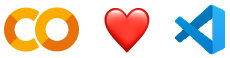

Try the new [Google Colab extension](https://marketplace.visualstudio.com/items?itemName=Google.colab) for Visual Studio Code. You can get up and running in just a few clicks:

*  In VS Code, open the ***Extensions*** view and search for 'Google Colab' to install.
*  Open the kernel selector by creating or opening any `.ipynb` notebook file in your local workspace and either running a cell or clicking the ***Select Kernel*** button in the top right.
*  Click ***Colab*** and then select your desired runtime, sign in with your Google account, and you're all set!

See more details in our [announcement blog here](https://developers.googleblog.com/google-colab-is-coming-to-vs-code).

# Access Popular LLMs via Google-Colab-AI Without an API Key

Users with Colab's paid plans have free access to most popular LLMs via google-colab-ai Python library. For more details, refer to the [getting started with google colab ai](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/Getting_started_with_google_colab_ai.ipynb).

In [ ]:
from google.colab import ai
response = ai.generate_text("What is the capital of France?")
print(response)

## Faster GPUs

Users who have purchased one of Colab's paid plans have access to faster GPUs and more memory. You can upgrade your notebook's GPU settings in `Runtime > Change runtime type` in the menu to select from several accelerator options, subject to availability.

The free of charge version of Colab grants access to Nvidia's T4 GPUs subject to quota restrictions and availability.

You can see what GPU you've been assigned at any time by executing the following cell. If the execution result of running the code cell below is "Not connected to a GPU", you can change the runtime by going to `Runtime > Change runtime type` in the menu to enable a GPU accelerator, and then re-execute the code cell.


In [ ]:
gpu_info = !nvidia-smi
gpu_info = '\n'.join(gpu_info)
if gpu_info.find('failed') >= 0:
  print('Not connected to a GPU')
else:
  print(gpu_info)

In order to use a GPU with your notebook, select the `Runtime > Change runtime type` menu, and then set the hardware accelerator to the desired option.

## More memory

Users who have purchased one of Colab's paid plans have access to high-memory VMs when they are available. More powerful GPUs are always offered with high-memory VMs.



You can see how much memory you have available at any time by running the following code cell. If the execution result of running the code cell below is "Not using a high-RAM runtime", then you can enable a high-RAM runtime via `Runtime > Change runtime type` in the menu. Then select High-RAM in the Runtime shape toggle button. After, re-execute the code cell.


In [ ]:
import psutil

ram_gb = psutil.virtual_memory().total / 1e9
print('Your runtime has {:.1f} gigabytes of available RAM\n'.format(ram_gb))

if ram_gb < 20:
  print('Not using a high-RAM runtime')
else:
  print('You are using a high-RAM runtime!')

## Longer runtimes

All Colab runtimes are reset after some period of time (which is faster if the runtime isn't executing code). Colab Pro and Pro+ users have access to longer runtimes than those who use Colab free of charge.

## Background execution

Colab Pro+ users have access to background execution, where notebooks will continue executing even after you've closed a browser tab. This is always enabled in Pro+ runtimes as long as you have compute units available.



## Relaxing resource limits in Colab Pro

Your resources are not unlimited in Colab. To make the most of Colab, avoid using resources when you don't need them. For example, only use a GPU when required and close Colab tabs when finished.



If you encounter limitations, you can relax those limitations by purchasing more compute units via Pay As You Go. Anyone can purchase compute units via [Pay As You Go](https://colab.research.google.com/signup); no subscription is required.

## Send us feedback!

If you have any feedback for us, please let us know. The best way to send feedback is by using the Help > 'Send feedback...' menu. If you encounter usage limits in Colab Pro consider subscribing to Pro+.

If you encounter errors or other issues with billing (payments) for Colab Pro, Pro+, or Pay As You Go, please email [colab-billing@google.com](mailto:colab-billing@google.com).

## More Resources

### Working with Notebooks in Colab
- [Overview of Colab](/notebooks/basic_features_overview.ipynb)
- [Guide to Markdown](/notebooks/markdown_guide.ipynb)
- [Importing libraries and installing dependencies](/notebooks/snippets/importing_libraries.ipynb)
- [Saving and loading notebooks in GitHub](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/colab-github-demo.ipynb)
- [Interactive forms](/notebooks/forms.ipynb)
- [Interactive widgets](/notebooks/widgets.ipynb)

<a name="working-with-data"></a>
### Working with Data
- [Loading data: Drive, Sheets, and Google Cloud Storage](/notebooks/io.ipynb)
- [Charts: visualizing data](/notebooks/charts.ipynb)
- [Getting started with BigQuery](/notebooks/bigquery.ipynb)

### Machine Learning Crash Course
These are a few of the notebooks from Google's online Machine Learning course. See the [full course website](https://developers.google.com/machine-learning/crash-course/) for more.
- [Intro to Pandas DataFrame](https://colab.research.google.com/github/google/eng-edu/blob/main/ml/cc/exercises/pandas_dataframe_ultraquick_tutorial.ipynb)
- [Intro to RAPIDS cuDF to accelerate pandas](https://nvda.ws/rapids-cudf)
- [Getting Started with cuML's accelerator mode](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cuml_sklearn_colab_demo.ipynb)


<a name="using-accelerated-hardware"></a>
### Using Accelerated Hardware
- [Train a CNN to classify handwritten digits on the MNIST dataset using Flax NNX API](https://colab.research.google.com/github/google/flax/blob/main/docs_nnx/mnist_tutorial.ipynb)
- [Train a Vision Transformer (ViT) for image classification with JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_Vision_transformer.ipynb)
- [Text classification with a transformer language model using JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_transformer_text_classification.ipynb)

<a name="machine-learning-examples"></a>

## Machine Learning Examples

A few featured examples:

- [Train a miniGPT language model with JAX AI Stack](https://docs.jaxstack.ai/en/latest/JAX_for_LLM_pretraining.html)
- [LoRA/QLoRA finetuning for LLM using Tunix](https://github.com/google/tunix/blob/main/examples/qlora_gemma.ipynb)
- [Parameter-efficient fine-tuning of Gemma with LoRA and QLoRA](https://keras.io/examples/keras_recipes/parameter_efficient_finetuning_of_gemma_with_lora_and_qlora/)
- [Loading Hugging Face Transformers Checkpoints](https://keras.io/keras_hub/guides/hugging_face_keras_integration/)
- [8-bit Integer Quantization in Keras](https://keras.io/guides/int8_quantization_in_keras/)
- [Float8 training and inference with a simple Transformer model](https://keras.io/examples/keras_recipes/float8_training_and_inference_with_transformer/)
- [Pretraining a Transformer from scratch with KerasHub](https://keras.io/keras_hub/guides/transformer_pretraining/)
- [Simple MNIST convnet](https://keras.io/examples/vision/mnist_convnet/)
- [Image classification from scratch using Keras 3](https://keras.io/examples/vision/image_classification_from_scratch/)
- [Image Classification with KerasHub](https://keras.io/keras_hub/guides/classification_with_keras_hub/)
